In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
%pip install openpyxl

covid = pd.read_csv("daily-new-confirmed-covid-19-cases-per-million-people.csv")
schiphol = pd.read_excel("Monthly_traffic_data_1992-current-2.xlsx")

Note: you may need to restart the kernel to use updated packages.


In [21]:
covid = pd.read_csv("daily-new-confirmed-covid-19-cases-per-million-people.csv")
covid["Day"] = pd.to_datetime(covid["Day"])
covid_nl = covid.loc[covid["Entity"] == "Netherlands"].copy().sort_values("Day")
covid_nl["Datum"] = (covid_nl["Day"].dt.to_period("M").dt.to_timestamp())
covid_maand = (covid_nl.groupby("Datum", as_index=False)["New cases (per 1M)"].mean().rename(columns={"New cases (per 1M)": "Covid_per_miljoen"}))

schiphol_raw = pd.read_excel(
    "Monthly_traffic_data_1992-current-2.xlsx",
    sheet_name="Standard&Poors",
    header=8
)

schiphol = schiphol_raw.iloc[:, [0, 1, 6, 7, 8, 10, 11]].copy()
schiphol.columns = [
    "Jaar",
    "Maand",
    "Europa",
    "Intercontinentaal",
    "Totaal",
    "OD",
    "Transfer"
]

schiphol["Jaar"] = pd.to_numeric(schiphol["Jaar"], errors="coerce").ffill()

maanden = {
    "January": 1,
    "February": 2,
    "March": 3,
    "April": 4,
    "May": 5,
    "June": 6,
    "July": 7,
    "August": 8,
    "September": 9,
    "October": 10,
    "November": 11,
    "December": 12
}

schiphol = schiphol.loc[schiphol["Maand"].isin(maanden)].copy()
schiphol["Jaar"] = schiphol["Jaar"].astype(int)
schiphol["Maandnummer"] = schiphol["Maand"].map(maanden)

schiphol["Datum"] = pd.to_datetime({
    "year": schiphol["Jaar"],
    "month": schiphol["Maandnummer"],
    "day": 1
})

categorieen = ["Europa", "Intercontinentaal", "Totaal", "OD", "Transfer"]

for kolom in categorieen:
    schiphol[kolom] = pd.to_numeric(
        schiphol[kolom], errors="raise"
    )

schiphol = schiphol.sort_values("Datum")

if schiphol["Datum"].duplicated().any():
    raise ValueError("Er staan dubbele maanden in de Schiphol-data.")

referentie = schiphol.loc[
    schiphol["Jaar"] == 2019
].set_index("Maandnummer")

if len(referentie) != 12:
    raise ValueError("Voor 2019 zijn niet alle twaalf maanden beschikbaar.")

for kolom in categorieen:
    basis = schiphol["Maandnummer"].map(referentie[kolom])
    schiphol[f"{kolom}_index"] = schiphol[kolom] / basis * 100

pandemie = schiphol.loc[
    schiphol["Jaar"].between(2020, 2022)
].merge(
    covid_maand,
    on="Datum",
    how="left",
    validate="one_to_one"
)

print("De data zijn klaar voor de grafieken.")

De data zijn klaar voor de grafieken.


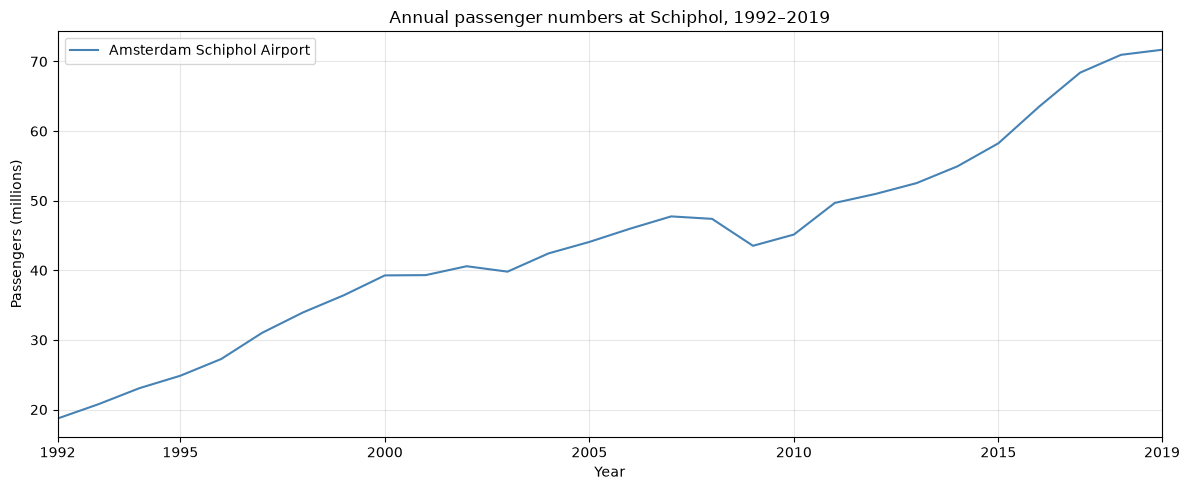

In [22]:
voor_covid = schiphol.loc[
    schiphol["Jaar"].between(1992, 2019)
]

jaar_totalen = (
    voor_covid.groupby("Jaar", as_index=False)["Totaal"].sum()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    jaar_totalen["Jaar"],
    jaar_totalen["Totaal"] / 1_000_000,
    label="Amsterdam Schiphol Airport",
    color="steelblue",
    linewidth=1.5
)

ax.set_title("Annual passenger numbers at Schiphol, 1992–2019")
ax.set_xlabel("Year")
ax.set_ylabel("Passengers (millions)")
ax.legend()
ax.grid(alpha=0.3)

ax.set_xlim(1992, 2019)
ax.set_xticks([1992, 1995, 2000, 2005, 2010, 2015, 2019])
fig.tight_layout()
fig.savefig("figure/schiphol_annual_passengers.png", dpi=300, bbox_inches="tight")
plt.show()

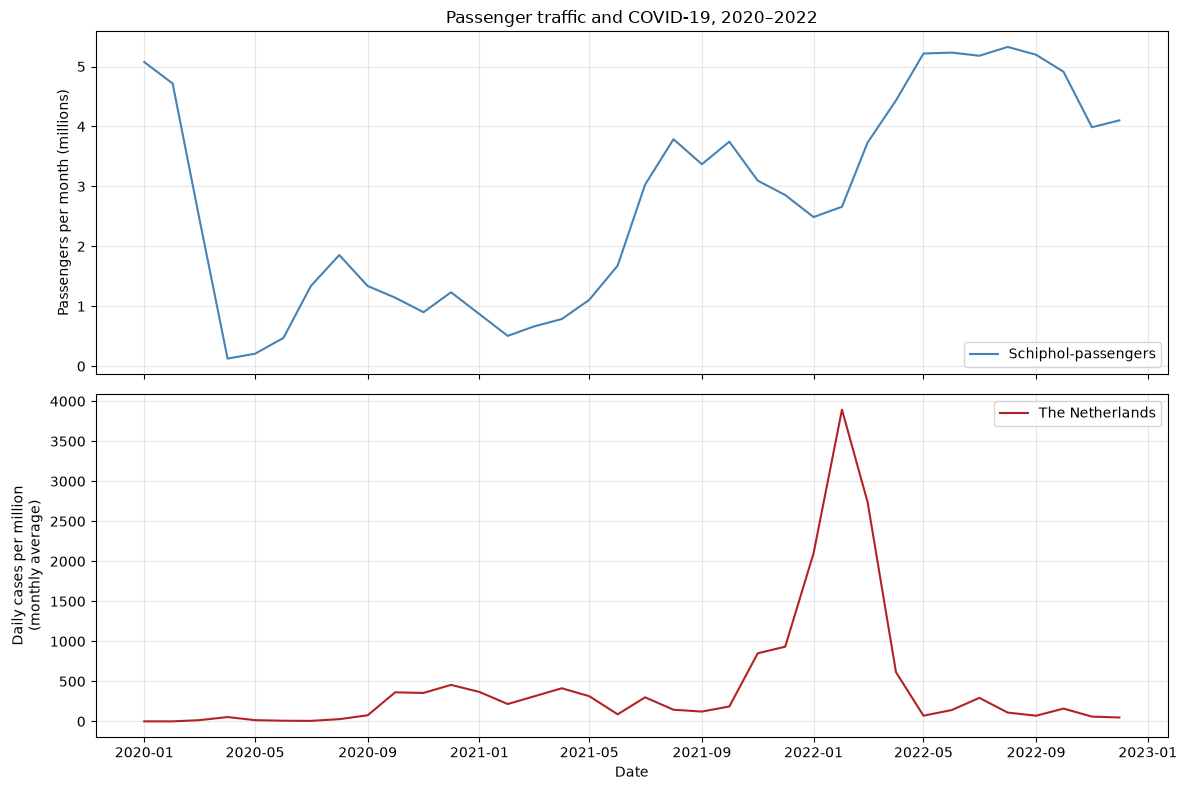

In [23]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True
)

ax1.plot(
    pandemie["Datum"],
    pandemie["Totaal"] / 1_000_000,
    label="Schiphol-passengers",
    color="steelblue",
    linewidth=1.5
)

ax1.set_title("Passenger traffic and COVID-19, 2020–2022")
ax1.set_ylabel("Passengers per month (millions)")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(
    pandemie["Datum"],
    pandemie["Covid_per_miljoen"],
    label="The Netherlands",
    color="firebrick",
    linewidth=1.5
)

ax2.set_xlabel("Date")
ax2.set_ylabel("Daily cases per million\n(monthly average)")
ax2.legend()
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

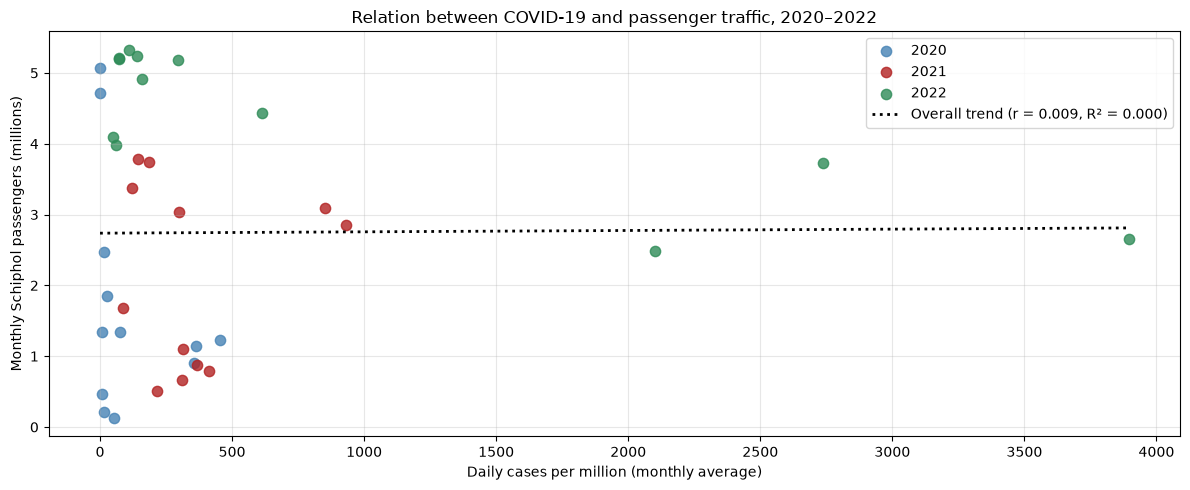

In [24]:
fig, ax = plt.subplots(figsize=(12, 5))

for jaar, kleur in [
    (2020, "steelblue"),
    (2021, "firebrick"),
    (2022, "seagreen")
]:
    data = pandemie.loc[pandemie["Jaar"] == jaar]

    ax.scatter(
        data["Covid_per_miljoen"],
        data["Totaal"] / 1_000_000,
        label=str(jaar),
        color=kleur,
        s=55,
        alpha=0.8
    )

data_totaal = pandemie.loc[
    pandemie["Jaar"].between(2020, 2022),
    ["Covid_per_miljoen", "Totaal"]
].dropna()

x = data_totaal["Covid_per_miljoen"].to_numpy()
y = data_totaal["Totaal"].to_numpy() / 1_000_000

helling, intercept = np.polyfit(x, y, 1)
voorspeld = helling * x + intercept
ss_tot = np.sum((y - y.mean()) ** 2)
r2 = (
    1 - np.sum((y - voorspeld) ** 2) / ss_tot
    if ss_tot > 0 else np.nan
)

x_lijn = np.linspace(x.min(), x.max(), 100)

r = np.corrcoef(x, y)[0, 1]

ax.plot(
    x_lijn,
    helling * x_lijn + intercept,
    label=f"Overall trend (r = {r:.3f}, R² = {r2:.3f})",
    color="black",
    linestyle=":",
    linewidth=2
)

ax.set_title("Relation between COVID-19 and passenger traffic, 2020–2022")
ax.set_xlabel("Daily cases per million (monthly average)")
ax.set_ylabel("Monthly Schiphol passengers (millions)")
ax.legend()
ax.grid(alpha=0.3)

from pathlib import Path

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
fig.savefig(
    "figure/covid_passengers_total.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

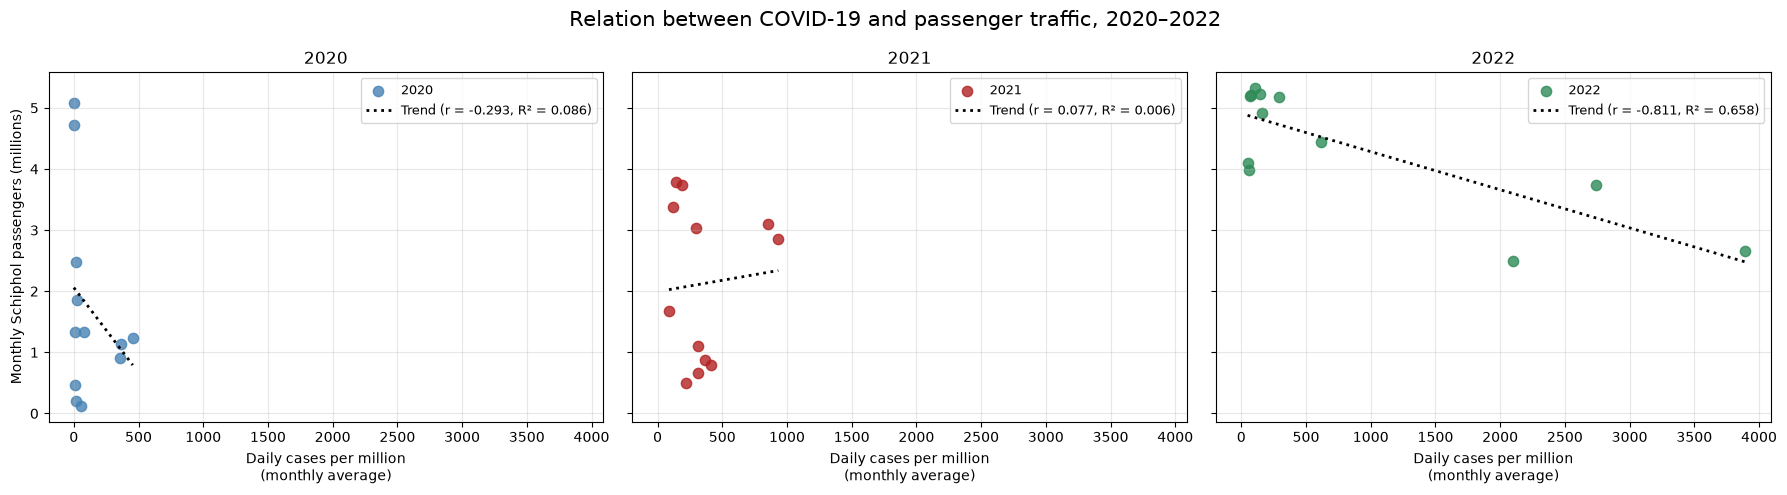

In [25]:
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5), sharex=True, sharey=True
)

for ax, jaar, kleur in zip(
    axes,
    [2020, 2021, 2022],
    ["steelblue", "firebrick", "seagreen"]
):
    data = pandemie.loc[
        pandemie["Jaar"] == jaar,
        ["Covid_per_miljoen", "Totaal"]
    ].dropna()

    x = data["Covid_per_miljoen"].to_numpy()
    y = data["Totaal"].to_numpy() / 1_000_000

    ax.scatter(
        x,
        y,
        label=str(jaar),
        color=kleur,
        s=55,
        alpha=0.8
    )

    helling, intercept = np.polyfit(x, y, 1)
    voorspeld = helling * x + intercept
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = (
        1 - np.sum((y - voorspeld) ** 2) / ss_tot
        if ss_tot > 0 else np.nan
    )

    x_lijn = np.linspace(x.min(), x.max(), 100)
    r = np.corrcoef(x, y)[0, 1]

    ax.plot(
        x_lijn,
        helling * x_lijn + intercept,
        label=f"Trend (r = {r:.3f}, R² = {r2:.3f})",
        color="black",
        linestyle=":",
        linewidth=2
    )

    ax.set_title(str(jaar))
    ax.set_xlabel("Daily cases per million\n(monthly average)")
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Monthly Schiphol passengers (millions)")

fig.suptitle(
    "Relation between COVID-19 and passenger traffic, 2020–2022",
    fontsize=15
)

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
fig.savefig(
    "figure/covid_passengers_per_year.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

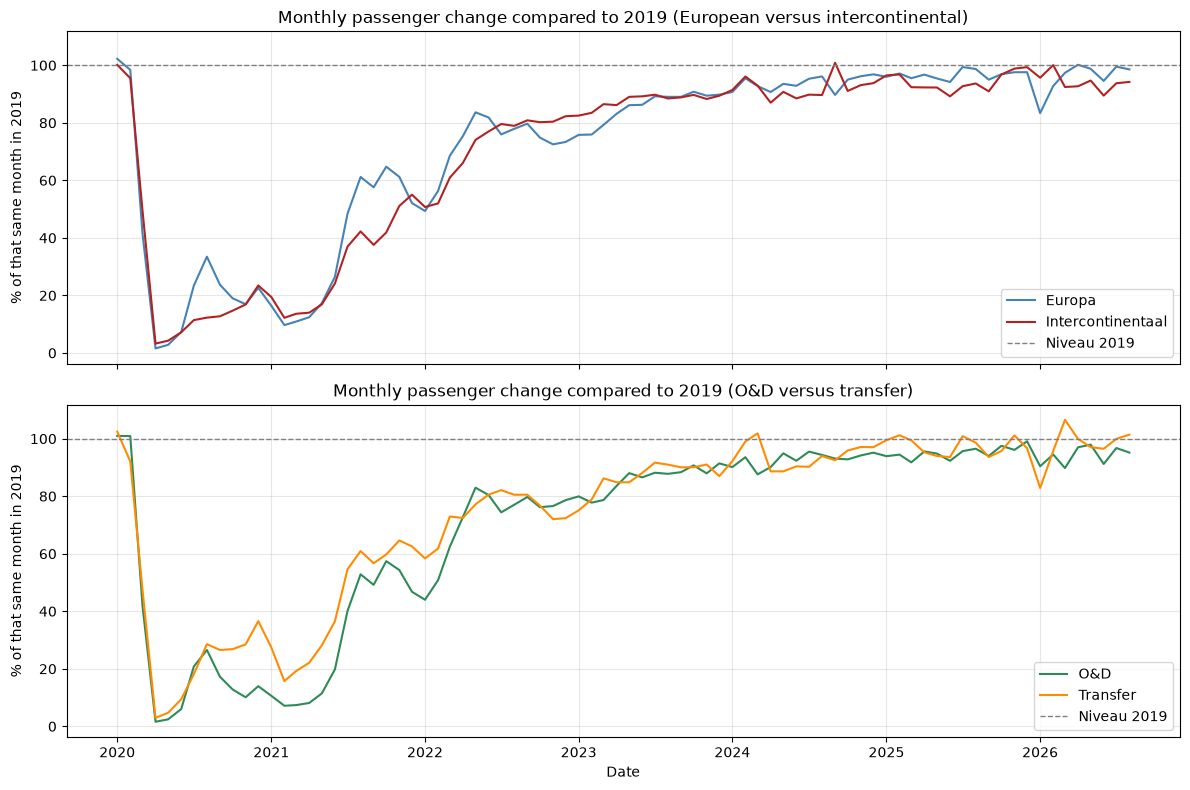

In [26]:
groepen = schiphol.loc[
    schiphol["Jaar"] >= 2020
].copy()

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 8), sharex=True, sharey=True
)

ax1.plot(
    groepen["Datum"],
    groepen["Europa_index"],
    label="Europa",
    color="steelblue",
    linewidth=1.5
)

ax1.plot(
    groepen["Datum"],
    groepen["Intercontinentaal_index"],
    label="Intercontinentaal",
    color="firebrick",
    linewidth=1.5
)

ax1.set_title("Monthly passenger change compared to 2019 (European versus intercontinental)")
ax1.set_ylabel("% of that same month in 2019")

ax2.plot(
    groepen["Datum"],
    groepen["OD_index"],
    label="O&D",
    color="seagreen",
    linewidth=1.5
)

ax2.plot(
    groepen["Datum"],
    groepen["Transfer_index"],
    label="Transfer",
    color="darkorange",
    linewidth=1.5
)

ax2.set_title("Monthly passenger change compared to 2019 (O&D versus transfer)")
ax2.set_xlabel("Date")
ax2.set_ylabel("% of that same month in 2019")

for ax in [ax1, ax2]:
    ax.axhline(
        100,
        color="gray",
        linestyle="--",
        linewidth=1,
        label="Niveau 2019"
    )
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

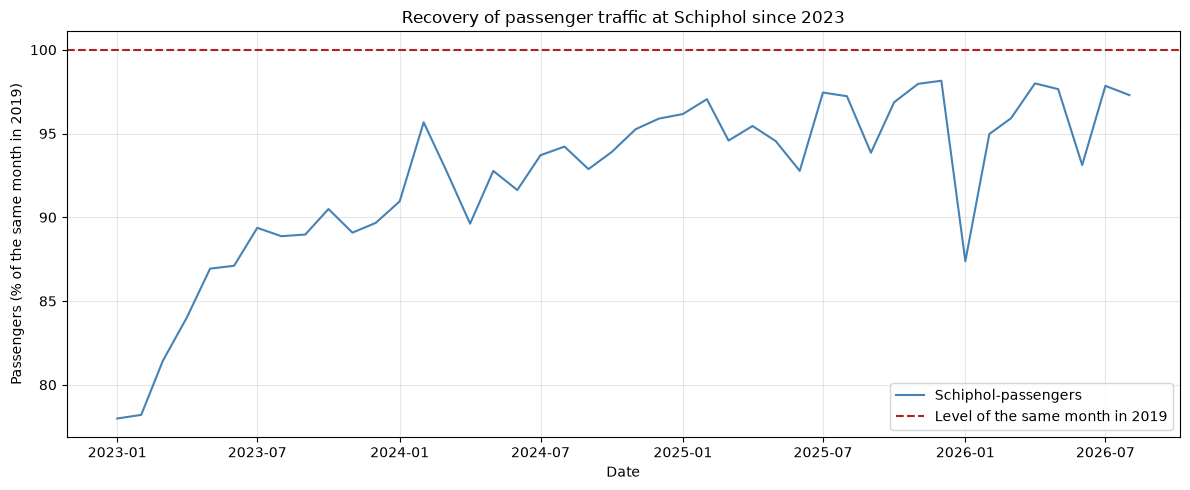

In [27]:
herstel = schiphol.loc[
    schiphol["Jaar"] >= 2023
].copy()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    herstel["Datum"],
    herstel["Totaal_index"],
    label="Schiphol-passengers",
    color="steelblue",
    linewidth=1.5
)

ax.axhline(
    100,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label="Level of the same month in 2019"
)

ax.set_title("Recovery of passenger traffic at Schiphol since 2023")
ax.set_xlabel("Date")
ax.set_ylabel("Passengers (% of the same month in 2019)")
ax.legend()
ax.grid(alpha=0.3)

from pathlib import Path

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
fig.savefig(
    "figure/schiphol_recovery_since_2023.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

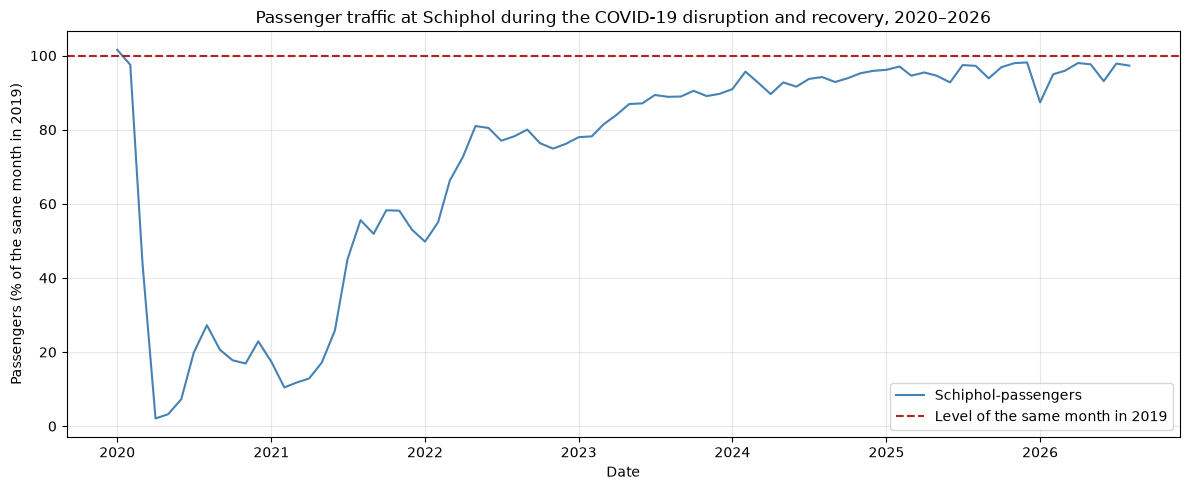

In [28]:
vanaf_covid = schiphol.loc[
    schiphol["Jaar"] >= 2020
].copy().sort_values("Datum")

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    vanaf_covid["Datum"],
    vanaf_covid["Totaal_index"],
    label="Schiphol-passengers",
    color="steelblue",
    linewidth=1.5
)

ax.axhline(
    100,
    color="firebrick",
    linestyle="--",
    linewidth=1.5,
    label="Level of the same month in 2019"
)

ax.set_title("Passenger traffic at Schiphol during the COVID-19 disruption and recovery, 2020–2026")
ax.set_xlabel("Date")
ax.set_ylabel("Passengers (% of the same month in 2019)")
ax.legend()
ax.grid(alpha=0.3)

from pathlib import Path

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()
fig.savefig(
    "figure/schiphol_disruption_and_recovery.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [29]:
# select passengers from 2019 to 2025
# 2019 pre-covid, 2020-2022 pandamic, 2023-2025 recovery-period

years = list(range(2019,2026))

monthly_data = schiphol.loc[
    schiphol['Jaar'].isin(years),
    ['Jaar', 'Maandnummer', 'Totaal']
].copy()

monthly_data['Totaal'] = pd.to_numeric(
    monthly_data['Totaal'],
    errors='coerce'
)

monthly_data = monthly_data.sort_values(
    ['Jaar', 'Maandnummer']
)

# check if each year contains 12 months

for year in years:

    year_data = monthly_data.loc[
        monthly_data["Jaar"] == year
    ]

    number_of_months = year_data["Maandnummer"].nunique()
    missing_passengers = year_data["Totaal"].isna().sum()

    print(
        f"{year}: {number_of_months} months, "
        f"{missing_passengers} missing values"
    )

    if number_of_months != 12 or missing_passengers > 0:
        print(f"WARNING: Incomplete data for {year}")
    else:
        print(f"Data for {year} is complete.")

print("\nData completeness check finished.")


# passenger numbers in millions

monthly_data['Passengers_millions'] = (
    monthly_data['Totaal'] / 1_000_000
)


2019: 12 months, 0 missing values
Data for 2019 is complete.
2020: 12 months, 0 missing values
Data for 2020 is complete.
2021: 12 months, 0 missing values
Data for 2021 is complete.
2022: 12 months, 0 missing values
Data for 2022 is complete.
2023: 12 months, 0 missing values
Data for 2023 is complete.
2024: 12 months, 0 missing values
Data for 2024 is complete.
2025: 12 months, 0 missing values
Data for 2025 is complete.

Data completeness check finished.


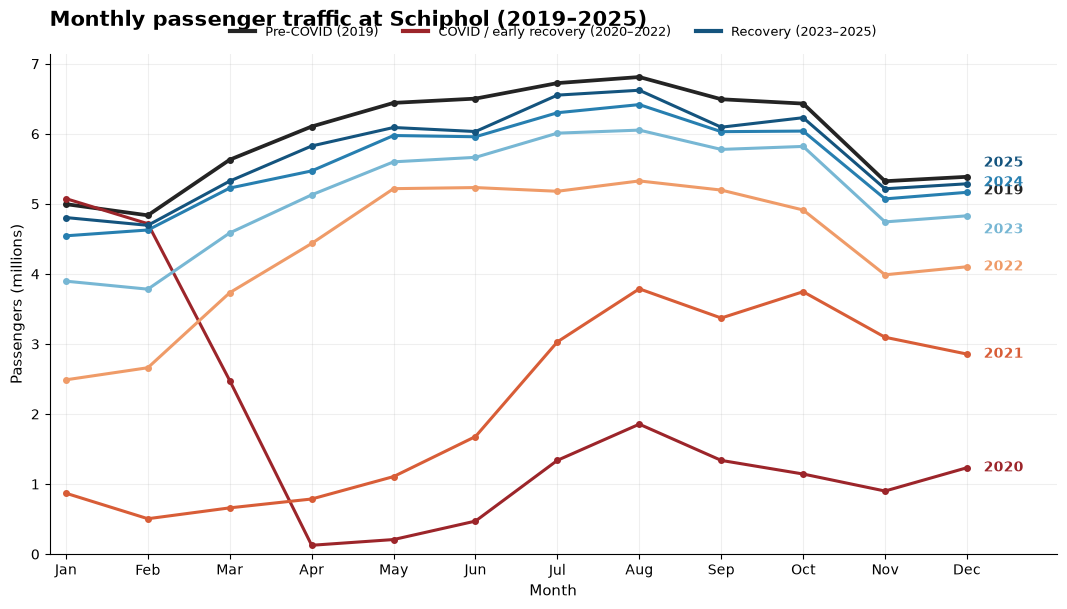

In [30]:
# Colors are devided into three periods
# Black: pre covid (2019)
# Red/orange: Covid and early recovery (2020-2022)
# Blue: Recovery (2023-2025)

colors = {
    2019: "#242424",
    2020: "#9C252A",
    2021: "#D85D37",
    2022: "#EF9B68",
    2023: "#77B7D4",
    2024: "#277FB0",
    2025: "#14547E"
}

months = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

# Visualization seasonality
# code for the graph that compared monthly passenger traffic at schiphol.
# before, during and after covid. 

from matplotlib.lines import Line2D

ig, ax = plt.subplots(figsize=(13, 6.5))

for year in years:

    year_data = monthly_data.loc[
        monthly_data["Jaar"] == year
    ].sort_values("Maandnummer")

    ax.plot(
        year_data["Maandnummer"],
        year_data["Passengers_millions"],
        color=colors[year],
        linewidth=2.7 if year == 2019 else 2.2,
        marker="o",
        markersize=4
    )

label_offsets = {
    2019: -10,
    2020: 0,
    2021: 0,
    2022: 0,
    2023: -10,
    2024: 7,
    2025: 15
}

for year in years:

    year_data = monthly_data.loc[
        monthly_data["Jaar"] == year
    ].sort_values("Maandnummer")

    if year_data.empty:
        continue

    last = year_data.iloc[-1]

    ax.annotate(
        str(year),
        xy=(last["Maandnummer"],
            last["Passengers_millions"]),
        xytext=(12, label_offsets[year]),
        textcoords="offset points",
        color=colors[year],
        fontsize=10,
        fontweight="bold",
        va="center",
        ha="left"
    )


ax.set_title(
    "Monthly passenger traffic at Schiphol (2019–2025)",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=20
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Passengers (millions)", fontsize=11)

ax.set_xticks(range(1, 13))
ax.set_xticklabels(months)

ax.set_xlim(0.8, 13.1)
ax.set_ylim(bottom=0)

ax.grid(alpha=0.2)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend_elements = [
    Line2D(
        [0], [0],
        color=colors[2019],
        lw=3,
        label="Pre-COVID (2019)"
    ),
    Line2D(
        [0], [0],
        color=colors[2020],
        lw=3,
        label="COVID / early recovery (2020–2022)"
    ),
    Line2D(
        [0], [0],
        color=colors[2025],
        lw=3,
        label="Recovery (2023–2025)"
    )
]

ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=3,
    frameon=False,
    fontsize=9
)

Path("figure").mkdir(exist_ok=True)

fig.tight_layout()

fig.savefig(
    "figure/schiphol_monthly_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Historical data check passed.


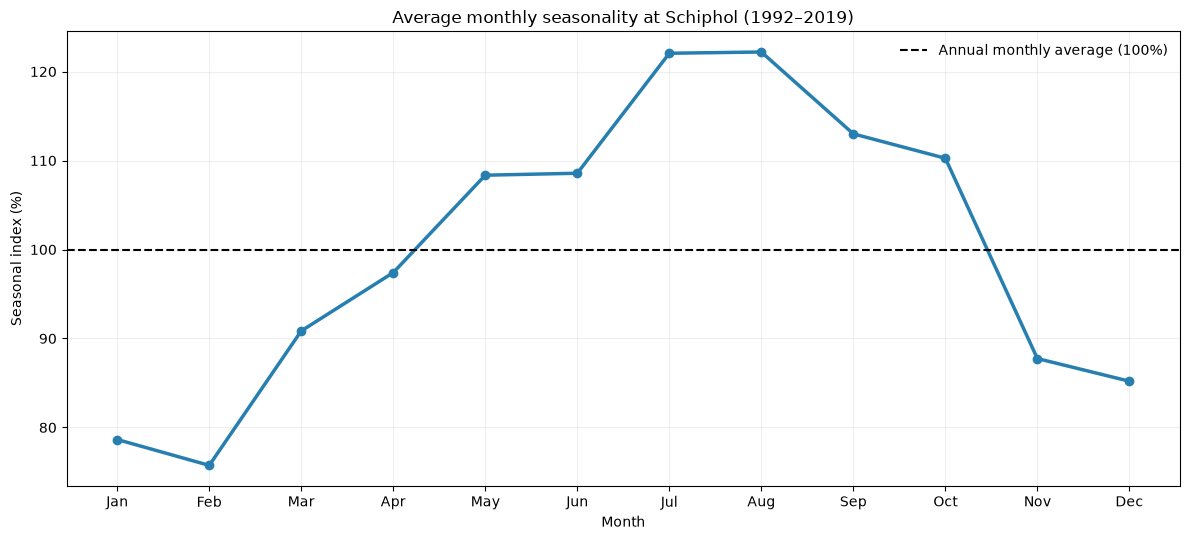

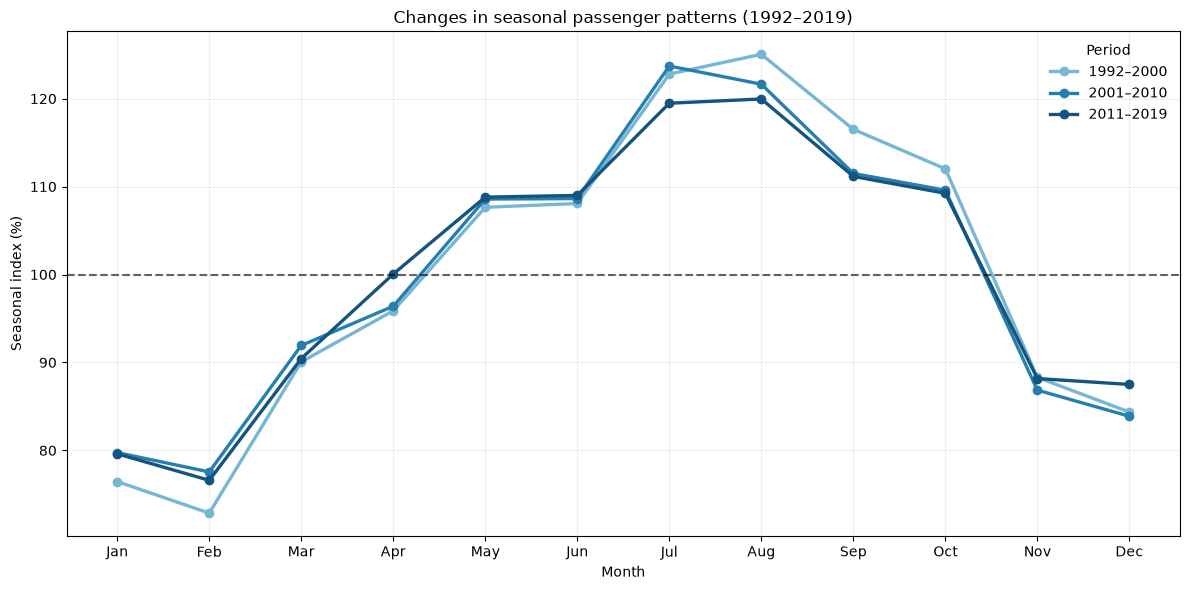


HISTORICAL SEASONALITY SUMMARY
   Period Peak_month  Peak_index Lowest_month  Lowest_index  Mean_absolute_deviation
1992–2000        Aug      125.04          Feb         72.87                    15.35
2001–2010        Jul      123.71          Feb         77.55                    13.94
2011–2019        Aug      119.96          Feb         76.60                    12.95

Historical seasonality analysis completed.


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

Path("figure").mkdir(exist_ok=True)


#select data

hist_data = schiphol.loc[
    schiphol["Jaar"].between(1992, 2019),
    ["Jaar", "Maandnummer", "Totaal"]
].copy()

hist_data["Totaal"] = pd.to_numeric(
    hist_data["Totaal"],
    errors="coerce"
)

hist_data = hist_data.sort_values(
    ["Jaar", "Maandnummer"]
)



if hist_data.duplicated(
    ["Jaar", "Maandnummer"]
).any():
    raise ValueError("Duplicate year-month observations found.")

hist_check = hist_data.groupby("Jaar").agg(
    Months=("Maandnummer", "nunique"),
    Missing=("Totaal", lambda x: x.isna().sum())
)

if (
    len(hist_check) != 28
    or (hist_check["Months"] != 12).any()
    or (hist_check["Missing"] > 0).any()
):
    raise ValueError("Incomplete historical data.")

print("Historical data check passed.")

#seasonal index

hist_data["Yearly_monthly_avg"] = (
    hist_data.groupby("Jaar")["Totaal"]
    .transform("mean")
)

hist_data["Seasonal_index"] = (
    hist_data["Totaal"]
    / hist_data["Yearly_monthly_avg"]
    * 100
)

hist_months = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]


#monthly average

hist_average = (
    hist_data.groupby("Maandnummer")["Seasonal_index"]
    .mean()
    .reindex(range(1, 13))
)

fig_hist_avg, ax_hist_avg = plt.subplots(figsize=(12, 5.5))

ax_hist_avg.plot(
    hist_average.index,
    hist_average.values,
    color="#277FB0",
    marker="o",
    linewidth=2.5
)

ax_hist_avg.axhline(
    100,
    color="black",
    linestyle="--",
    label="Annual monthly average (100%)"
)

ax_hist_avg.set_title(
    "Average monthly seasonality at Schiphol (1992–2019)"
)

ax_hist_avg.set_xlabel("Month")
ax_hist_avg.set_ylabel("Seasonal index (%)")

ax_hist_avg.set_xticks(range(1, 13))
ax_hist_avg.set_xticklabels(hist_months)

ax_hist_avg.grid(alpha=0.2)
ax_hist_avg.legend(frameon=False)

fig_hist_avg.tight_layout()

fig_hist_avg.savefig(
    "figure/schiphol_monthly_seasonality.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


#compare the three periods

hist_data["Period"] = pd.cut(
    hist_data["Jaar"],
    bins=[1991, 2000, 2010, 2019],
    labels=[
        "1992–2000",
        "2001–2010",
        "2011–2019"
    ]
)

hist_periods = (
    hist_data.groupby(
        ["Maandnummer", "Period"],
        observed=True
    )["Seasonal_index"]
    .mean()
    .unstack("Period")
    .reindex(range(1, 13))
)

hist_colors = {
    "1992–2000": "#77B7D4",
    "2001–2010": "#277FB0",
    "2011–2019": "#14547E"
}

fig_hist_period, ax_hist_period = plt.subplots(figsize=(12, 6))

for hist_period in hist_periods.columns:

    ax_hist_period.plot(
        hist_periods.index,
        hist_periods[hist_period],
        color=hist_colors[str(hist_period)],
        marker="o",
        linewidth=2.4,
        label=str(hist_period)
    )

ax_hist_period.axhline(
    100,
    color="black",
    linestyle="--",
    alpha=0.6
)

ax_hist_period.set_title(
    "Changes in seasonal passenger patterns (1992–2019)"
)

ax_hist_period.set_xlabel("Month")
ax_hist_period.set_ylabel("Seasonal index (%)")

ax_hist_period.set_xticks(range(1, 13))
ax_hist_period.set_xticklabels(hist_months)

ax_hist_period.grid(alpha=0.2)
ax_hist_period.legend(title="Period", frameon=False)

fig_hist_period.tight_layout()

fig_hist_period.savefig(
    "figure/schiphol_seasonality_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


hist_strength = (
    hist_periods.sub(100)
    .abs()
    .mean(axis=0)
)

hist_summary_rows = []

for hist_period in hist_periods.columns:

    hist_indices = hist_periods[hist_period]

    hist_peak_month = int(hist_indices.idxmax())
    hist_low_month = int(hist_indices.idxmin())

    hist_summary_rows.append({
        "Period": str(hist_period),
        "Peak_month": hist_months[hist_peak_month - 1],
        "Peak_index": hist_indices.max(),
        "Lowest_month": hist_months[hist_low_month - 1],
        "Lowest_index": hist_indices.min(),
        "Mean_absolute_deviation": hist_strength[hist_period]
    })

hist_summary = pd.DataFrame(hist_summary_rows)

print("\nHISTORICAL SEASONALITY SUMMARY")
print(hist_summary.round(2).to_string(index=False))


hist_summary.to_csv(
    "figure/schiphol_seasonality_summary.csv",
    index=False
)

print("\nHistorical seasonality analysis completed.")
